# Detection: GRAM hyperparameter comparisons

本 notebook 只展示完整 GRAM 与 baseline 的检测比较。候选为 **β × k 的 35 个完整模型设置**：
β=0、0.1、1、10、100、1000、10000；k=10、25、50、100、250。
保持完整 margin + gradient + identity 核和 adaptive 权重；β=0 使用等价的 risk-only 记录。
组件删减、固定权重和其他 acquisition 控制见 `ablation.ipynb`，时间开销见 `runtime.ipynb`。

所有图先对每次运行从首个 0.1% 检查点到该噪声率对应最大预算做归一化梯形积分，
再对同一配置实际可用的 seeds 求算术平均：有几个 seed 就平均几个，不选择最佳 seed。

保留原第一组，并新增每个 β 使用一个通用 k 的对照：

1. **原第一组**：每个固定 β 下，先对三种噪声等权平均，再为每个数据集 / 噪声比例选择最优 k。
2. **新增通用 k 对照**：每个固定 β、k 下，先得到与第一组相同口径的各场景展示点，
   再对 6 个数据集 × 2 种噪声比例的 12 个展示点等权平均 AUPRC + Precision，选出一个通用 k。
   该 β 在所有数据集、噪声比例和噪声类型上使用同一个 k，再将 20% 和 40% 噪声率的结果分别放在同一张图的上、下两排。
选择指标为最终展示点的 **预算平均 AUPRC + 预算平均 Precision**；精确并列时优先 AUPRC、Precision，再优先较小 k。
每个点的 AUPRC 和 Precision 来自同一个 k；β 不参与择优，七个 β 全部展示。通用 k 是当前全部结果上的描述性选择，不是独立验证集上的调参结果。
baseline 同样先平均实际可用 seeds，再等权平均三种噪声；不选择最佳 checkpoint。

图仅导出为 PDF，输出至 `analysis/figures/detection/comparison/`。

baseline 颜色沿用 `runtime.ipynb`，GRAM 使用饱和度更高的杏橙色。计算中间表保留在 notebook 内存中，不写独立 CSV。

统一选参接口为 `scripts/best_k.py`（命令行）和 `scripts.best_k`（Python）。
所有选择只使用完整 adaptive 核的 β × k 检测结果，先平均实际可用 seeds，以 AUPRC + Precision 择优。
下游默认调用 `scenario`：按数据集 / 噪声类型 / 比例 / β 查询，252 条结果保留在 `scenario_best_k` 中。
本 notebook 原第一组使用同一接口的 `noise_mean`；通用 k 对照使用 `global`，维持原有两套展示口径。
精确并列时依次比较 AUPRC、Precision，再选较小 k。`detect_result_vis_isolation.ipynb` 保持显式数值快照，独立运行。

磁盘导出仅保存 PDF 图，不生成 JSON 或其他格式的辅助文件；中间数据保留在 notebook 内存中。


In [1]:
%matplotlib inline

import json
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D


DATASETS = ["cifar10", "cifar100", "atis", "qnli", "adult", "letter"]
NOISE_TYPES = ["symmetric", "pairflip", "instance"]
RHOS = [0.2, 0.4]
BASELINE_METHODS = [
    "aum_b", "el2n_b", "early_loss_b", "forgetting_b",
    "knn_label_disagreement_b", "moderate_b", "cleanlab_b", "misdetect_b",
    "dalc", "dalc_frozen", "robust_alc", "robust_alc_frozen",
    "active_label_cleaning", "active_label_correction",
    "graph_label_propagation", "cleannet",
]
METHOD_ORDER = ["ours", *BASELINE_METHODS]
REQUIRED_SEEDS = [0]  # The completed grid must include seed=0; additional complete seeds are averaged.
GRAM_BETAS = [0.0, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]
BETA_MARKERS = {0.0: "X", 0.1: "o", 1.0: "s", 10.0: "^",
                100.0: "D", 1000.0: "P", 10000.0: "v"}
SELECTION_MODES = ["noise_mean_first", "global_k_per_beta"]


def beta_series(beta):
    return f"gram_beta{beta:g}"


PLOT_SERIES_ORDER = [beta_series(beta) for beta in GRAM_BETAS] + BASELINE_METHODS
DATASET_LABELS = {
    "cifar10": "CIFAR-10", "cifar100": "CIFAR-100", "atis": "ATIS",
    "qnli": "QNLI", "adult": "Adult", "letter": "Letter",
}
METHOD_LABELS = {
    "ours": "GRAM (Ours)",
    "aum_b": "AUM-B", "el2n_b": "EL2N-B",
    "early_loss_b": "Early-Loss-B", "forgetting_b": "Forgetting-B",
    "knn_label_disagreement_b": "kNN Disagr.-B", "moderate_b": "Moderate-B",
    "cleanlab_b": "CleanLab-B", "misdetect_b": "MisDetect-B",
    "dalc": "DALC", "dalc_frozen": "DALC (frz.)",
    "robust_alc": "Robust ALC", "robust_alc_frozen": "Robust ALC (frz.)",
    "active_label_cleaning": "Active Cleaning",
    "active_label_correction": "Active Correction",
    "graph_label_propagation": "Graph LP", "cleannet": "CleanNet",
}


def find_project_root(start):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "results" / "detection").is_dir():
            return candidate
    raise FileNotFoundError("Cannot find results/detection from the current directory.")


PROJECT_ROOT = find_project_root(Path.cwd())
RESULTS_ROOT = PROJECT_ROOT / "results" / "detection"
OUTPUT_DIR = PROJECT_ROOT / "analysis" / "figures" / "detection"
GRID_OUTPUT_DIR = OUTPUT_DIR / "comparison"
GRID_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from config.methods import (GRAM_DATASET_NEIGHBORS, GRAM_GRID_NEIGHBORS,
                            gram_grid_variants, method_config as effective_method_config)
from src.utils.run_logging import completed_run_exists
from scripts.best_k import budget_averages, k_candidates, select_k
from IPython.display import display
GRID_VARIANTS_BY_DATASET = {
    dataset: gram_grid_variants(kernels=("adaptive",), acquisitions=("repair_iv",))
    for dataset in DATASETS
}


EXPECTED_BUDGETS = {
    rho: np.array([0.001, 0.005, 0.01, 0.025]
                  + [round(0.05 * i, 12) for i in range(1, round(rho / 0.05) + 1)])
    for rho in RHOS
}

# Same method/color/marker mapping in all comparison figures; shapes also distinguish methods.
# Follow analysis/runtime.ipynb baseline families: score calibration blue, status inference green,
# label correction purple, GRAM saturated apricot. Shapes continue to distinguish individual methods.
METHOD_COLORS = {
    "aum_b": "#C7DDE9",
    "el2n_b": "#BDD5E3",
    "early_loss_b": "#B2CCDD",
    "forgetting_b": "#A8C3D6",
    "cleanlab_b": "#9DBAD0",
    "knn_label_disagreement_b": "#93B1C9",
    "moderate_b": "#89A8C2",
    "misdetect_b": "#CBDCCB",
    "cleannet": "#B7CFBF",
    "graph_label_propagation": "#A4C1B3",
    "dalc_frozen": "#DED5E9",
    "dalc": "#D4CAE3",
    "robust_alc_frozen": "#CABFDD",
    "robust_alc": "#BFB4D6",
    "active_label_cleaning": "#B5A9D0",
    "active_label_correction": "#AA9EC9",
    "ours": "#E8895B"
}
GRAM_COLOR = METHOD_COLORS["ours"]
BASELINE_COLORS = [METHOD_COLORS[method] for method in BASELINE_METHODS]
BASELINE_MARKERS = [
    "o", "s", "^", "v", "D", "P", "X", "<",
    ">", "h", "p", "8", "*", "H", "d", (5, 0),
]
BASELINE_STYLES = dict(zip(BASELINE_METHODS, zip(BASELINE_COLORS, BASELINE_MARKERS)))

plt.rcParams.update({
    "figure.dpi": 140, "savefig.dpi": 300,
    "font.family": "DejaVu Sans", "font.weight": "normal",
    "font.size": 14, "axes.titlesize": 16, "axes.titleweight": "normal",
    "axes.labelsize": 15, "axes.labelweight": "normal",
    "axes.edgecolor": "#222222", "axes.linewidth": 0.75,
    "axes.facecolor": "white", "figure.facecolor": "white",
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 12, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

In [2]:
# Read every complete seed for each expected per-dataset configuration.
# Exact directory depths exclude source_metadata and shared training artifacts.
REQUIRED_FILES = ("run_args.json", "config.json", "metrics.csv", "queries.csv",
                  "predictions.csv", "summary.json")
REQUIRED_COLUMNS = ["configured_budget_fraction", "verification_fraction",
                    "unverified_auprc", "query_precision"]
RUN_KEYS = ["dataset", "noise_type", "rho", "setting", "seed"]
run_rows, all_checkpoint_frames = [], []
expected_configs = {
    variant: json.loads(json.dumps(effective_method_config("ours", variant)))
    for variants in GRID_VARIANTS_BY_DATASET.values() for variant in variants
}
expected_runs = []

run_specs, excluded_seed_dirs = [], []
for dataset in DATASETS:
    candidates = [("ours", variant) for variant in GRID_VARIANTS_BY_DATASET[dataset]]
    candidates += [(method, "") for method in BASELINE_METHODS]
    for (method, variant), noise_type, rho in product(candidates, NOISE_TYPES, RHOS):
        base = RESULTS_ROOT / dataset / noise_type / f"rho{rho:g}" / method
        if method == "ours":
            base /= variant
        available = []
        for directory in sorted(base.glob("seed*")):
            suffix = directory.name.removeprefix("seed")
            if not directory.is_dir() or not suffix.isdigit():
                continue
            seed = int(suffix)
            if completed_run_exists(directory, protocol="full_pool_detection", required_files=REQUIRED_FILES):
                available.append(seed)
                run_specs.append((dataset, method, variant, noise_type, rho, seed, directory))
            else:
                excluded_seed_dirs.append({"source": directory.relative_to(PROJECT_ROOT).as_posix(),
                                           "status": "incomplete seed excluded"})
        if not set(REQUIRED_SEEDS) <= set(available):
            raise ValueError(f"Required completed seed is missing: {base}; observed={available}")

for dataset, method, variant, noise_type, rho, seed, directory in run_specs:
    is_gram = method == "ours"
    if not completed_run_exists(directory, protocol="full_pool_detection", required_files=REQUIRED_FILES):
        raise ValueError(f"Missing/incomplete plotting run: {directory}")
    metrics_path = directory / "metrics.csv"
    config = json.loads((directory / "config.json").read_text())
    summary = json.loads((directory / "summary.json").read_text())
    identity = dict(dataset=dataset, noise_type=noise_type, rho=rho, method=method, seed=seed)
    if any(summary.get(key) != value for key, value in identity.items()):
        raise ValueError(f"Summary identity mismatch: {directory}")
    if (config.get("dataset") != dataset or config.get("method") != method
        or config.get("protocol") != "full_pool_detection"
        or summary.get("protocol") != "full_pool_detection"
        or any(config["scenario"].get(k) != identity[k] for k in ("noise_type", "rho", "seed"))):
        raise ValueError(f"Configuration identity mismatch: {directory}")
    mconfig = config["method_config"]
    if is_gram and (config.get("gram_variant") != variant
                    or summary.get("gram_variant") != variant
                    or mconfig != expected_configs[variant]):
        raise ValueError(f"GRAM effective configuration mismatch: {directory}")
    frame = pd.read_csv(metrics_path).sort_values("configured_budget_fraction")
    expected = EXPECTED_BUDGETS[rho]
    configured = frame["configured_budget_fraction"].to_numpy(float)
    if (len(configured) != len(expected) or not np.allclose(configured, expected)
        or not np.allclose(configured, summary["budgets"])
        or not np.allclose(configured, config["scenario"]["budgets"])):
        raise ValueError(f"Missing/unexpected budget checkpoints: {metrics_path}")
    values = frame[REQUIRED_COLUMNS].to_numpy(float)
    if not np.isfinite(values).all() or not ((values >= 0) & (values <= 1)).all():
        raise ValueError(f"Nonfinite/out-of-range metrics: {metrics_path}")
    counts = frame["verification_budget"].to_numpy(int)
    if (not np.all(np.diff(counts) > 0)
        or counts[-1] != summary["actual_budget"]
        or counts.tolist() != config["budget_checkpoint_target_counts"]):
        raise ValueError(f"Actual query budget mismatch: {metrics_path}")
    x = counts / summary["sample_count"]
    if not np.allclose(x, frame["verification_fraction"], atol=1e-5):
        raise ValueError(f"Verification fractions do not match counts: {metrics_path}")
    precision = frame["queried_mislabels_found"].to_numpy(int) / counts
    if not np.allclose(precision, frame["query_precision"], atol=1e-5):
        raise ValueError(f"Query precision does not match counts: {metrics_path}")
    frame["verification_fraction"] = x
    frame["query_precision"] = precision
    y = frame[["unverified_auprc", "query_precision"]].to_numpy(float)
    budget_means = budget_averages(frame.to_dict("records"), summary["sample_count"])
    fingerprint = summary.get("shared_training_artifact_fingerprint")
    if is_gram and (not fingerprint or fingerprint != config["training_protocol"].get("shared_training_artifact_fingerprint")):
        raise ValueError(f"Missing/mismatched training fingerprint: {directory}")
    context = json.dumps({
        "dataset_config": config["dataset_config"], "model_config": config["model_config"],
        "sample_count": summary["sample_count"], "errors": summary["injected_mislabel_count"],
        "budgets": configured.tolist(), "query_counts": counts.tolist(),
        "fingerprint": fingerprint,
    }, sort_keys=True)
    setting = f"ours/{variant}" if is_gram else method
    record = {
        **identity, "setting": setting, "gram_variant": variant,
        "auprc": budget_means[0], "precision": budget_means[1],
        "budget_start": x[0], "budget_end": x[-1],
        "max_budget_configured": rho, "checkpoint_count": len(frame),
        "reference_k": GRAM_DATASET_NEIGHBORS[dataset] if is_gram else np.nan,
        "graph_neighbors": mconfig.get("graph_neighbors", np.nan),
        "acquisition": mconfig.get("acquisition", ""),
        "iv_beta": mconfig.get("iv_beta", np.nan),
        "kernel_components": "+".join(mconfig.get("active_kernel_components", [])),
        "kernel_weights": mconfig.get("kernel_weights", ""),
        "training_fingerprint": fingerprint, "pairing_context": context,
        "historical_result_reused": (directory / "result_reuse.json").is_file(),
        "training_fingerprint_overridden": "fingerprint_override" in summary,
        "source": metrics_path.relative_to(PROJECT_ROOT).as_posix(),
    }
    run_rows.append(record)
    expected_runs.append(tuple(record[key] for key in RUN_KEYS))
    checkpoints = frame[["checkpoint", "configured_budget_fraction", "verification_fraction",
                         "unverified_auprc", "query_precision"]].rename(
        columns={"unverified_auprc": "auprc", "query_precision": "precision"})
    for name, value in record.items():
        if name not in ("auprc", "precision"):
            checkpoints[name] = value
    if is_gram:
        checkpoints["beta"] = mconfig["iv_beta"]
        all_checkpoint_frames.append(checkpoints)

run_summaries = pd.DataFrame(run_rows)
observed_runs = pd.MultiIndex.from_frame(run_summaries[RUN_KEYS])
expected_index = pd.MultiIndex.from_tuples(expected_runs, names=RUN_KEYS)
if observed_runs.has_duplicates or not expected_index.equals(observed_runs):
    raise ValueError("Duplicate or incomplete comparison grid")
SEEDS = sorted(run_summaries.seed.unique().tolist())
assert len(run_summaries) == len(run_specs)
grid_checkpoints = pd.concat(all_checkpoint_frames, ignore_index=True)
grid_runs = run_summaries[run_summaries.method.eq("ours")].copy()
pair_keys = ["dataset", "noise_type", "rho", "seed"]
if not grid_runs.groupby(pair_keys)["pairing_context"].nunique().eq(1).all():
    raise ValueError("GRAM controls are not paired on training/noise/budget context")
seed_coverage = (run_summaries.groupby(["dataset", "noise_type", "rho", "method", "gram_variant", "setting"],
                                     as_index=False, dropna=False)
                 .agg(seed_count=("seed", "nunique"), seeds=("seed", lambda x: ",".join(map(str, sorted(x.unique()))))))
grid_inventory = (grid_runs.groupby("dataset", as_index=False)
                  .agg(configurations=("gram_variant", "nunique"), completed_runs=("setting", "size"),
                       reference_k=("reference_k", "first")))
coverage_summary = (seed_coverage[seed_coverage.method.eq("ours")].groupby("dataset", as_index=False)
                    .agg(configuration_scenarios=("seed_count", "size"),
                         seed_count_min=("seed_count", "min"), seed_count_max=("seed_count", "max")))
grid_inventory = grid_inventory.merge(coverage_summary, on="dataset", validate="one_to_one")
assert grid_inventory.configurations.eq(35).all() and grid_inventory.configuration_scenarios.eq(210).all()
assert grid_inventory.seed_count_min.ge(1).all()
# Context JSON is checked in memory; source paths and fingerprints remain in the notebook DataFrames.
print(f"Loaded {len(grid_runs):,} GRAM grid runs and {len(run_summaries)-len(grid_runs):,} baseline runs; available seeds={SEEDS}.")
print("Each configuration averages all its completed seeds before configuration/checkpoint selection.")
display(grid_inventory)
assert grid_runs.kernel_components.eq("margin+gradient+identity").all()
assert grid_runs.kernel_weights.eq("adaptive").all()
assert grid_runs.acquisition.isin(["repair_plus_informative_value", "posterior_risk"]).all()

Loaded 1,908 GRAM grid runs and 1,728 baseline runs; available seeds=[0, 1, 2].
Each configuration averages all its completed seeds before configuration/checkpoint selection.


,dataset,configurations,completed_runs,reference_k,configuration_scenarios,seed_count_min,seed_count_max
0,adult,35,318,10.0,210,1,3
1,atis,35,318,250.0,210,1,3
2,cifar10,35,318,25.0,210,1,3
3,cifar100,35,318,100.0,210,1,3
4,letter,35,318,250.0,210,1,3
5,qnli,35,318,10.0,210,1,3


In [3]:
# Average seeds within each fixed configuration/noise/rate BEFORE selecting configurations.
eligible_mask = (run_summaries.method.eq("ours") & (
    (run_summaries.acquisition.eq("repair_plus_informative_value") & run_summaries.iv_beta.isin(GRAM_BETAS))
    | (run_summaries.acquisition.eq("posterior_risk") & run_summaries.iv_beta.eq(0))))
run_summaries["eligible_for_beta_curve"] = eligible_mask
seed_keys = ["dataset", "noise_type", "rho", "method", "setting", "gram_variant"]
seed_averaged_runs = (run_summaries.groupby(seed_keys, as_index=False, sort=True, dropna=False)
    .agg(auprc=("auprc", "mean"), precision=("precision", "mean"), seed_count=("seed", "nunique"),
         seeds=("seed", lambda v: ",".join(map(str, sorted(v.unique())))),
         graph_neighbors=("graph_neighbors", "first"), acquisition=("acquisition", "first"),
         iv_beta=("iv_beta", "first"), kernel_components=("kernel_components", "first"),
         kernel_weights=("kernel_weights", "first"), eligible_for_beta_curve=("eligible_for_beta_curve", "all"),
         historical_run_count=("historical_result_reused", "sum"),
         fingerprint_override_count=("training_fingerprint_overridden", "sum"),
         sources=("source", lambda v: " | ".join(sorted(v)))))
seed_averaged_runs["seed_count_max"] = seed_averaged_runs.seed_count
seed_averaged_runs["seed"] = np.nan  # Aggregated, never a selected seed.
seed_averaged_runs["selection_score"] = seed_averaged_runs.auprc + seed_averaged_runs.precision
# The notebook and downstream use the same Python API behind scripts/best_k.py.
selection_runs = grid_runs.to_dict("records")
gram_run_candidates = pd.DataFrame(k_candidates(selection_runs, scope="scenario"))
scenario_best_k = pd.DataFrame(select_k(gram_run_candidates.to_dict("records"), scope="scenario"))
assert len(scenario_best_k) == len(DATASETS) * len(NOISE_TYPES) * len(RHOS) * len(GRAM_BETAS)
assert set(gram_run_candidates.beta.unique()) == set(GRAM_BETAS)
beta_candidate_counts = (gram_run_candidates.groupby(["dataset", "beta"], as_index=False)
    .agg(config_count=("setting", "nunique"), min_seeds=("seed_count", "min"),
         max_seeds=("seed_count", "max"), configuration_scenarios=("setting", "size")))

candidate_keys = ["dataset", "rho", "method", "setting", "gram_variant"]
noise_averaged = (seed_averaged_runs.groupby(candidate_keys, as_index=False, sort=True, dropna=False)
    .agg(auprc=("auprc", "mean"), precision=("precision", "mean"), noise_count=("noise_type", "nunique"),
         seed_count=("seed_count", "min"), seed_count_max=("seed_count_max", "max"),
         historical_run_count=("historical_run_count", "sum"),
         fingerprint_override_count=("fingerprint_override_count", "sum"),
         graph_neighbors=("graph_neighbors", "first"), acquisition=("acquisition", "first"),
         iv_beta=("iv_beta", "first"), kernel_components=("kernel_components", "first"),
         kernel_weights=("kernel_weights", "first"), eligible_for_beta_curve=("eligible_for_beta_curve", "all"),
         sources=("sources", lambda v: " | ".join(sorted(v)))))
assert noise_averaged.noise_count.eq(len(NOISE_TYPES)).all()
noise_averaged["seed"] = np.nan
noise_averaged["selection_score"] = noise_averaged.auprc + noise_averaged.precision
gram_noise_candidates = pd.DataFrame(k_candidates(selection_runs, scope="noise_mean"))

# 1. Seed mean -> noise mean -> best configuration for each beta.
gram_mean_first = pd.DataFrame(select_k(gram_noise_candidates.to_dict("records"), scope="noise_mean"))
gram_mean_first["aggregation"] = "noise_mean_first"
gram_mean_first["noise_type"] = "all_three_averaged"
assert len(gram_mean_first) == len(DATASETS)*len(RHOS)*len(GRAM_BETAS)

# Each beta gets ONE k shared across all six datasets, both noise rates and all noise types.
# Evaluate each k using the same per-scenario coordinates shown by the first group,
# then give all 12 dataset/rho scenarios equal weight (not proportional to dataset size).
assert not gram_noise_candidates.duplicated(["dataset", "rho", "beta", "graph_neighbors"]).any()
global_k_candidates = pd.DataFrame(k_candidates(selection_runs, scope="global"))
assert len(global_k_candidates) == len(GRAM_BETAS) * len(GRAM_GRID_NEIGHBORS)
assert global_k_candidates.scenario_count.eq(len(DATASETS) * len(RHOS)).all()
assert global_k_candidates.dataset_count.eq(len(DATASETS)).all()
assert global_k_candidates.rho_count.eq(len(RHOS)).all()
global_k_candidates["selection_score"] = global_k_candidates.auprc + global_k_candidates.precision
global_k_candidates["setting"] = global_k_candidates.graph_neighbors.map(lambda k: f"k={int(k)}")
global_best_k = pd.DataFrame(select_k(global_k_candidates.to_dict("records"), scope="global"))
assert len(global_best_k) == len(GRAM_BETAS)
gram_global_k = gram_noise_candidates.merge(
    global_best_k[["beta", "graph_neighbors"]], on=["beta", "graph_neighbors"],
    how="inner", validate="many_to_one")
gram_global_k["aggregation"] = "global_k_per_beta"
gram_global_k["noise_type"] = "all_three_averaged"
assert len(gram_global_k) == len(DATASETS) * len(RHOS) * len(GRAM_BETAS)
assert gram_global_k.groupby("beta").graph_neighbors.nunique().eq(1).all()
# Per-scenario best k provides an upper bound on the same selection score.
local_global_check = gram_mean_first.merge(gram_global_k, on=["dataset", "rho", "beta"],
                                          suffixes=("_local", "_global"), validate="one_to_one")
assert (local_global_check.selection_score_local + 1e-12 >= local_global_check.selection_score_global).all()

# Baselines average all available seeds first, then give each noise type equal weight.
baseline_points = (noise_averaged[noise_averaged.method.isin(BASELINE_METHODS)]
    .groupby(["dataset", "rho", "method"], as_index=False)
    .agg(auprc=("auprc", "mean"), precision=("precision", "mean"),
         seed_count=("seed_count", "min"), seed_count_max=("seed_count_max", "max"),
         noise_count=("noise_count", "min")))
assert baseline_points.seed_count.ge(1).all()
baseline_points["gram_variant"] = ""
baseline_points["seed"] = np.nan
baseline_points["beta"] = np.nan
baseline_points["series"] = baseline_points.method

point_columns = ["dataset", "rho", "method", "series", "beta", "auprc", "precision", "aggregation",
                 "seed_count", "seed_count_max", "noise_count", "gram_variant", "seed"]
plot_frames = []
for mode, gram_points in [
    ("noise_mean_first", gram_mean_first.copy()),
    ("global_k_per_beta", gram_global_k.copy()),
]:
    gram_points["series"] = gram_points.beta.map(beta_series)
    plot_frames.extend([gram_points[point_columns], baseline_points.assign(aggregation=mode)[point_columns]])
plot_points = pd.concat(plot_frames, ignore_index=True)
plot_points["max_budget"] = plot_points.rho
gram_selected = pd.concat([gram_mean_first, gram_global_k], ignore_index=True)
assert len(plot_points) == len(SELECTION_MODES)*len(DATASETS)*len(RHOS)*len(PLOT_SERIES_ORDER)
assert not plot_points.duplicated(["aggregation", "dataset", "rho", "series"]).any()
assert np.isfinite(plot_points[["auprc", "precision"]].to_numpy()).all()
display(beta_candidate_counts)

,dataset,beta,config_count,min_seeds,max_seeds,configuration_scenarios
0,adult,0.0,5,1,3,30
1,adult,0.1,5,1,3,30
2,adult,1.0,5,3,3,30
3,adult,10.0,5,1,3,30
4,adult,100.0,5,1,3,30
5,adult,1000.0,5,1,1,30
6,adult,10000.0,5,1,1,30
7,atis,0.0,5,1,3,30
8,atis,0.1,5,1,3,30
9,atis,1.0,5,3,3,30


In [4]:
def legend_handles(mode="noise_mean_first"):
    from matplotlib.colors import to_hex, to_rgb

    # Slightly deepen legend swatches while retaining the existing hues.
    def legend_color(color):
        return to_hex(np.array(to_rgb(color)) * 0.88)

    gram_legend_color = GRAM_COLOR
    chosen_k = global_best_k.set_index("beta").graph_neighbors.to_dict()
    handles = [Line2D(
        [], [], color=gram_legend_color, linestyle="-", linewidth=1.5,
        marker=BETA_MARKERS[beta], markersize=6,
        markerfacecolor=gram_legend_color, markeredgecolor="black", markeredgewidth=0.6,
        label=(f"GRAM β={beta:g} (k={int(chosen_k[beta])})"
               if mode == "global_k_per_beta" else f"GRAM (Ours) β={beta:g}"),
    ) for beta in GRAM_BETAS]
    # Match runtime's family/method order; the seven GRAM settings form row three.
    runtime_baselines = [
        "aum_b", "el2n_b", "early_loss_b", "forgetting_b", "cleanlab_b",
        "knn_label_disagreement_b", "moderate_b", "misdetect_b", "cleannet",
        "graph_label_propagation", "dalc_frozen", "dalc", "robust_alc_frozen",
        "robust_alc", "active_label_cleaning", "active_label_correction",
    ]
    gram_handles, handles = handles, []
    for method in runtime_baselines:
        color, marker = BASELINE_STYLES[method]
        handles.append(Line2D(
            [], [], linestyle="none", marker=marker, markersize=7,
            markerfacecolor=legend_color(color), markeredgecolor="#34404B", markeredgewidth=0.5,
            label=METHOD_LABELS[method],
        ))
    return handles + gram_handles


def figure_stem(mode):
    stem = "detection_tradeoff_noise20_40_budget20_40"
    suffixes = {"noise_mean_first": "", "global_k_per_beta": "_global_k_per_beta"}
    if mode not in suffixes:
        raise ValueError(f"Unknown selection mode: {mode}")
    return stem + suffixes[mode]


def plot_tradeoff(mode="noise_mean_first"):
    row_rates = (0.2, 0.4)
    points = plot_points[plot_points["aggregation"].eq(mode)].copy()
    expected = len(row_rates) * len(DATASETS) * len(PLOT_SERIES_ORDER)
    if len(points) != expected:
        raise ValueError(f"Incomplete plotting data for mode={mode}")

    fig, axes = plt.subplots(2, 6, figsize=(19.5, 6.3), sharex=True, sharey=True)
    for row_index, rho in enumerate(row_rates):
        row_points = points[np.isclose(points["rho"], rho)]
        if len(row_points) != len(DATASETS) * len(PLOT_SERIES_ORDER):
            raise ValueError(f"Incomplete plotting data for rho={rho}, mode={mode}")
        for index, (ax, dataset) in enumerate(zip(axes[row_index], DATASETS)):
            panel = row_points[row_points["dataset"].eq(dataset)].set_index("series")
            for method in BASELINE_METHODS:
                row = panel.loc[method]
                color, marker = BASELINE_STYLES[method]
                ax.scatter(
                    row["auprc"], row["precision"], s=88, marker=marker,
                    facecolor=color, edgecolor="#34404B", linewidth=0.55,
                    alpha=0.9, zorder=3,
                )
            gram_panel = panel.loc[[beta_series(beta) for beta in GRAM_BETAS]]
            ax.plot(gram_panel["auprc"], gram_panel["precision"],
                    color=GRAM_COLOR, linewidth=1.5, alpha=0.95, zorder=4)
            for beta in GRAM_BETAS:
                row = panel.loc[beta_series(beta)]
                ax.scatter(
                    row["auprc"], row["precision"], s=80, marker=BETA_MARKERS[beta],
                    facecolor=GRAM_COLOR, edgecolor="black", linewidth=0.65, zorder=6,
                )

            ax.set_xlim(-0.03, 1.04)
            ax.set_ylim(-0.03, 1.04)
            ax.set_xticks(np.linspace(0, 1, 6))
            ax.set_yticks(np.linspace(0, 1, 6))
            ax.set_aspect("auto")
            ax.set_axisbelow(True)
            ax.grid(True, color="#C8C8C8", linestyle=":", linewidth=0.85, alpha=0.85)
            ax.tick_params(
                axis="both", direction="out", length=3, width=0.7, pad=2,
                bottom=True, left=True, top=False, right=False,
                labelbottom=True, labelleft=True, labelcolor="#283747",
            )
            xlabel = "Unverified AUPRC"
            if row_index == len(row_rates) - 1:
                xlabel += f"\n({chr(ord('a') + index)}) {DATASET_LABELS[dataset]}"
            ax.set_xlabel(xlabel, labelpad=5)
            ax.set_ylabel("Verified Precision", labelpad=5)
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_color("#222222")
                spine.set_linewidth(0.75)

    # Matplotlib fills columns first; pad and transpose to display rows left to right.
    handles = legend_handles(mode)
    legend_columns = 8
    legend_rows = int(np.ceil(len(handles) / legend_columns))
    handles += [Line2D([], [], linestyle="none", label=" ")
                for _ in range(legend_rows * legend_columns - len(handles))]
    ordered_handles = [handles[row * legend_columns + column]
                       for column in range(legend_columns) for row in range(legend_rows)]
    legend = fig.legend(
        handles=ordered_handles, loc="upper center", bbox_to_anchor=(0.5, 0.995),
        ncol=legend_columns, frameon=True, fancybox=False, framealpha=1,
        facecolor="white", edgecolor="#BBBBBB", fontsize=12,
        handlelength=1.7, handletextpad=0.5, columnspacing=0.8,
        labelspacing=0.45, borderpad=0.35,
    )
    legend.get_frame().set_linewidth(0.6)
    # Measure the legend so its gap to the panels stays small as labels change.
    fig.canvas.draw()
    legend_box = legend.get_window_extent(fig.canvas.get_renderer()).transformed(
        fig.transFigure.inverted()
    )
    panel_top = legend_box.y0 - 0.40 / fig.get_figheight()
    fig.subplots_adjust(
        left=0.052, right=0.993, top=panel_top, bottom=0.13,
        wspace=0.32, hspace=0.58,
    )

    # Row headings identify noise rates independently of dataset labels (a)-(f).
    for row_index, rho in enumerate(row_rates):
        row_box = axes[row_index, 0].get_position()
        fig.text(
            row_box.x0, row_box.y1 + 0.09 / fig.get_figheight(),
            f"{rho:.0%} noise rate", ha="left", va="bottom",
            fontsize=14, fontweight="bold", color="#222222",
        )

    stem = figure_stem(mode)
    fig.savefig(GRID_OUTPUT_DIR / f"{stem}.pdf", format="pdf",
                bbox_inches=None, pad_inches=0, facecolor="white")
    plt.show()
    plt.close(fig)
    return fig

## 第一组：预算平均，先平均噪声再择优

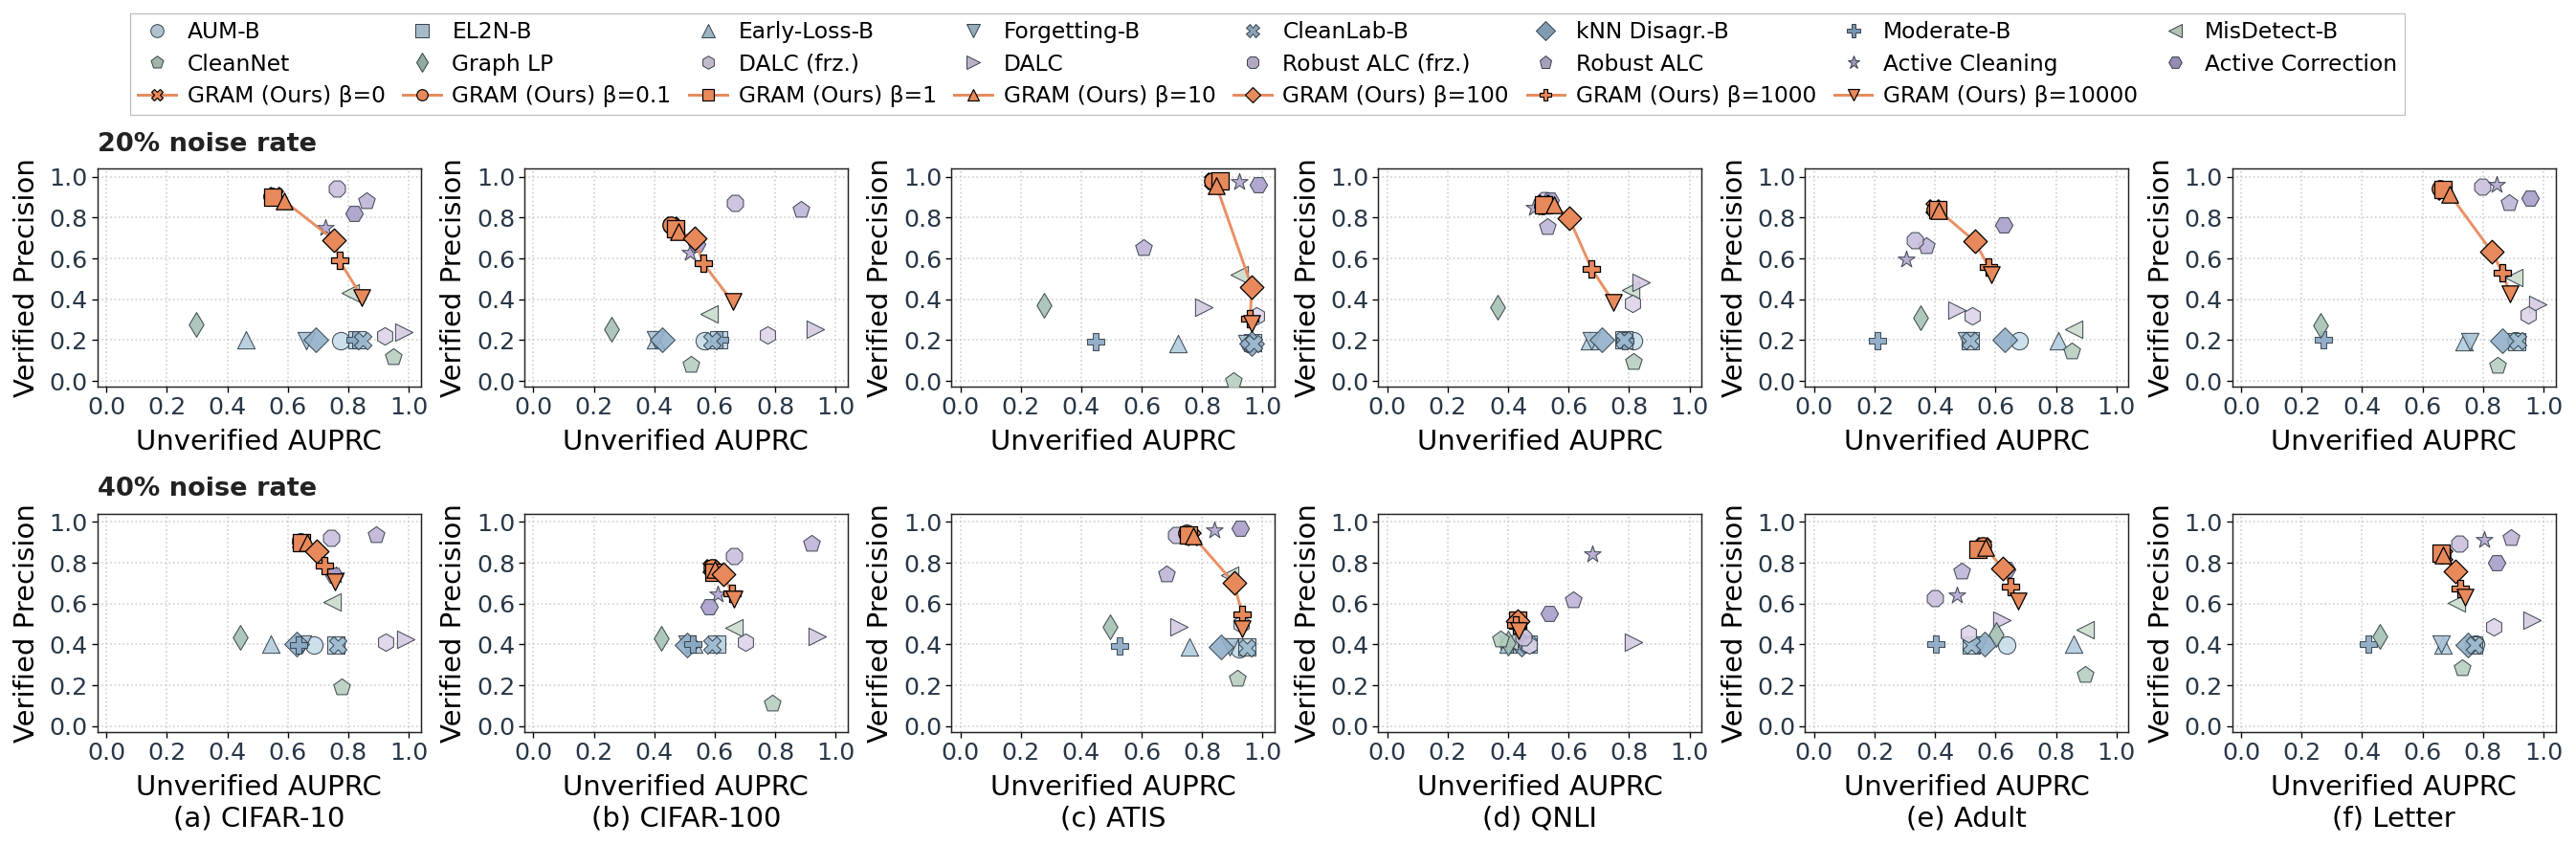

In [5]:
combined_figure = plot_tradeoff("noise_mean_first")


## 逐 β 的 k 选择：与第一组最终展示点一致

对每个数据集 / 噪声比例 / 固定 β，依次比较 k=10、25、50、100、250。
每个 k 都先在配置内平均实际可用 seeds，再对三种噪声等权平均；
以最终展示点的 AUPRC + Precision 选择 k，两个坐标共用同一个 k。
表格直接取自第一组已选中的配置，不再分噪声选 k，也不在 β 之间择优。

下面分别列出 20% 和 40% 噪声率下的选择。`first_group_best_k` DataFrame 保留全部 84 个展示点的
k、AUPRC、Precision、选择分数、可用 seed 数范围和原始路径，不导出独立 CSV。


In [6]:
# Report the exact k used by every first-group point, without another selection pass.
selection_columns = ["dataset", "rho", "beta", "graph_neighbors", "auprc", "precision",
                     "selection_score", "seed_count", "seed_count_max", "noise_count",
                     "gram_variant", "sources"]
first_group_best_k = gram_mean_first[selection_columns].copy()
assert len(first_group_best_k) == len(DATASETS) * len(RHOS) * len(GRAM_BETAS)
assert not first_group_best_k.duplicated(["dataset", "rho", "beta"]).any()
assert first_group_best_k.graph_neighbors.isin(GRAM_GRID_NEIGHBORS).all()
for rho in RHOS:
    choices = first_group_best_k[np.isclose(first_group_best_k.rho, rho)]
    k_table = choices.pivot(index="dataset", columns="beta", values="graph_neighbors")
    k_table = k_table.reindex(index=DATASETS, columns=GRAM_BETAS).astype(int)
    k_table.index = [DATASET_LABELS[dataset] for dataset in k_table.index]
    k_table.columns = [f"β={beta:g}" for beta in GRAM_BETAS]
    k_table.index.name = f"Noise rate {rho:.0%}: selected k"
    display(k_table)


,β=0,β=0.1,β=1,β=10,β=100,β=1000,β=10000
Noise rate 20%: selected k,,,,,,,
CIFAR-10,25,25,25,250,10,10,100
CIFAR-100,10,10,100,10,10,10,25
ATIS,250,250,250,250,100,10,10
QNLI,100,250,10,100,250,10,10
Adult,100,50,250,250,10,100,250
Letter,25,50,50,50,50,10,10


,β=0,β=0.1,β=1,β=10,β=100,β=1000,β=10000
Noise rate 40%: selected k,,,,,,,
CIFAR-10,100,100,10,100,100,250,10
CIFAR-100,250,100,250,100,100,10,50
ATIS,250,10,10,100,10,10,10
QNLI,50,50,250,50,50,10,10
Adult,25,25,10,100,250,50,25
Letter,250,25,250,50,250,10,10


## 新增：每个 β 选择一个通用 k

每个 β 独立选择 k，使用 6 个数据集 × 2 种噪声比例共 12 个展示点的平均 AUPRC + Precision。
每个候选展示点均先平均实际可用 seeds，再对三种噪声等权平均，沿用第一组的预算积分指标。
数据集、噪声比例各等权，不按样本数或 seed 数给某个场景额外权重。

选定后，同一 β 在全部数据集和两种噪声比例上固定使用该 k；不再按场景重新选择。
两种噪声比例合并为 2×6 数据集面板：上排 20%，下排 40%，展示全部 β 和相同 baseline。
图例中注明各 β 的通用 k；35 条候选得分、7 条最终选择、84 条场景来源分别保留在
`global_k_candidates`、`global_best_k`、`gram_global_k` DataFrame 中，不导出独立 CSV。


In [7]:
global_k_table = global_best_k[["beta", "graph_neighbors", "auprc", "precision", "selection_score", "scenario_count"]].copy()
global_k_table = global_k_table.sort_values("beta").rename(columns={
    "beta": "β", "graph_neighbors": "通用 k", "auprc": "12 场景平均 AUPRC",
    "precision": "12 场景平均 Precision", "selection_score": "平均 AUPRC + Precision",
    "scenario_count": "场景数"})
global_k_table["通用 k"] = global_k_table["通用 k"].astype(int)
display(global_k_table.reset_index(drop=True))


,β,通用 k,12 场景平均 AUPRC,12 场景平均 Precision,平均 AUPRC + Precision,场景数
0,0.0,10,0.586024,0.835620,1.421645,12
1,0.1,250,0.580754,0.840466,1.421220,12
2,1.0,250,0.584961,0.836158,1.421119,12
3,10.0,250,0.601501,0.823921,1.425422,12
4,100.0,10,0.677735,0.676521,1.354256,12
5,1000.0,10,0.709399,0.575190,1.284590,12
6,10000.0,10,0.739322,0.485500,1.224822,12


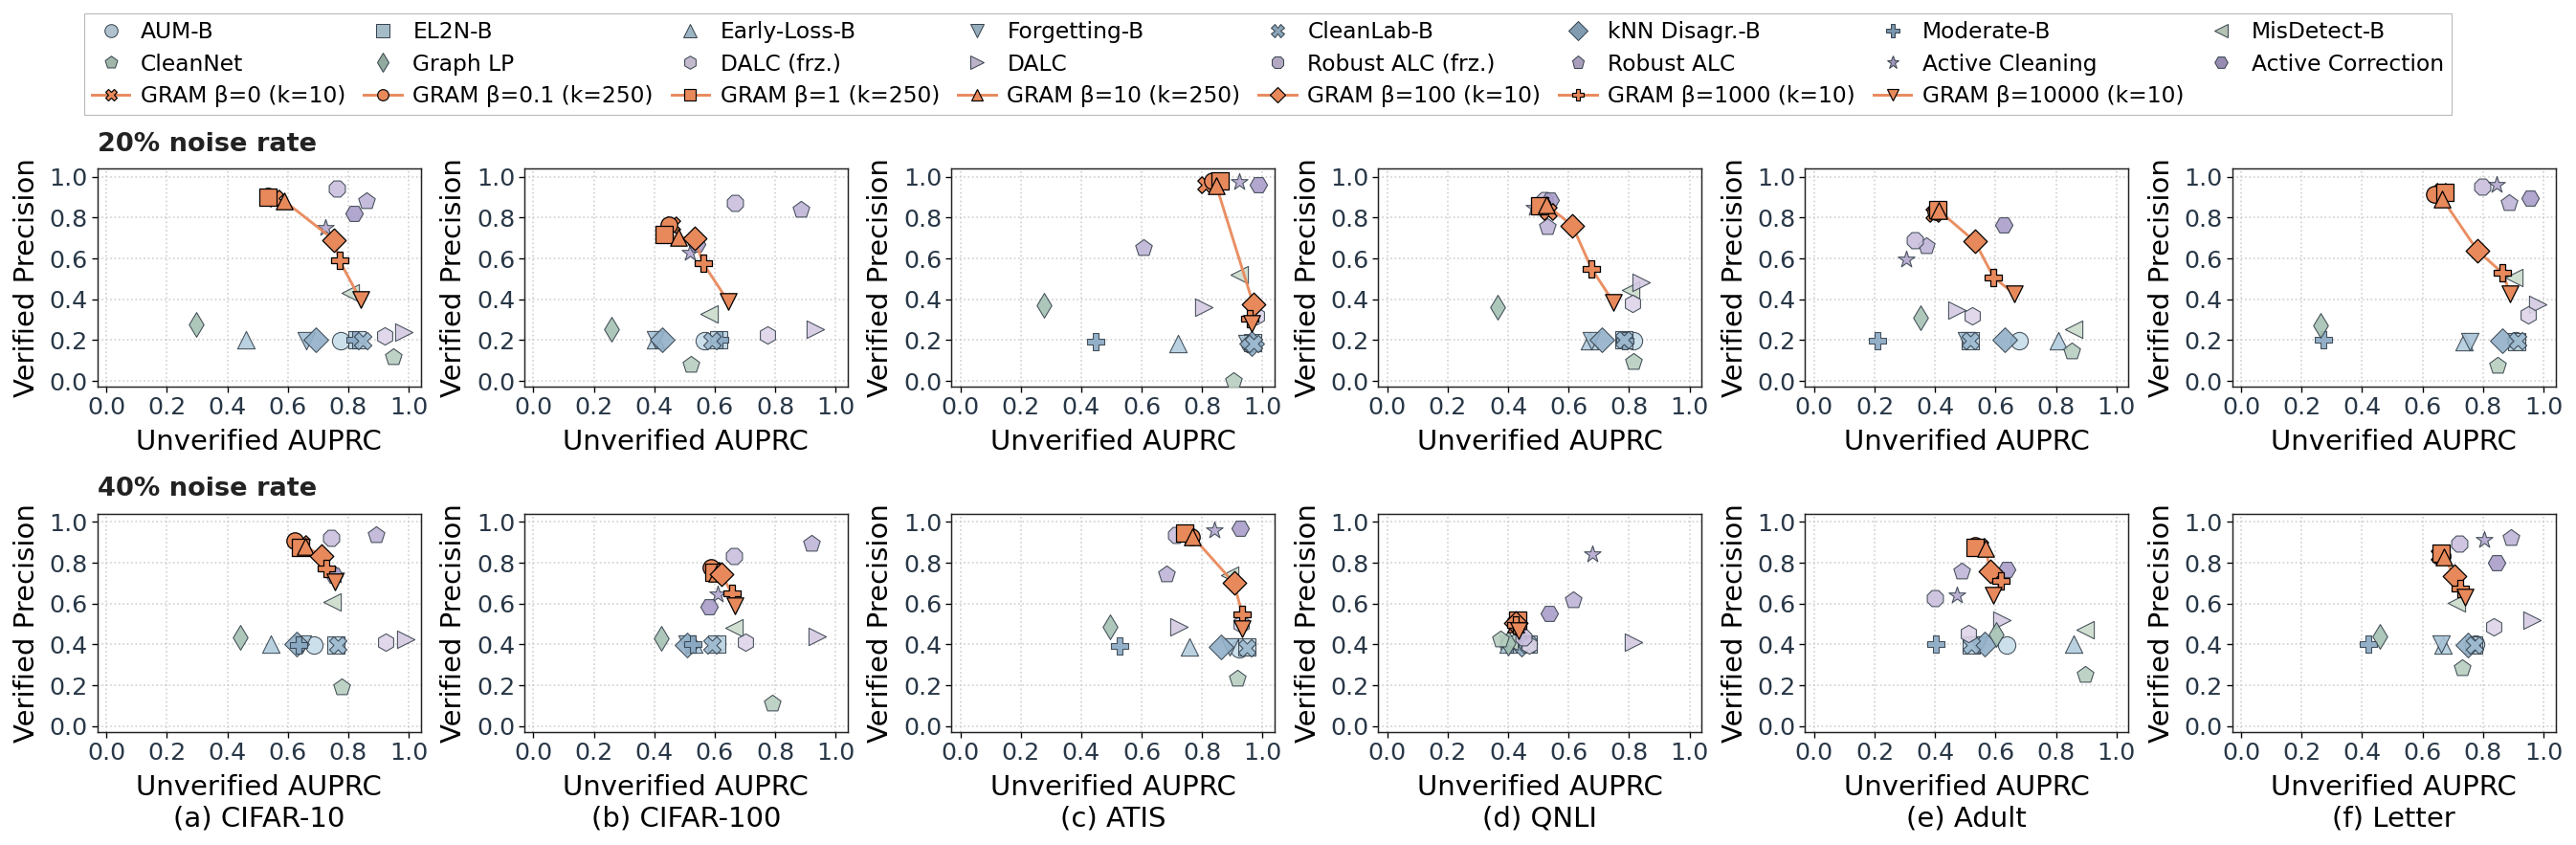

In [8]:
global_k_combined_figure = plot_tradeoff("global_k_per_beta")
